# Homework 4:  KNN Classification and a Streamlit Application

**Student Name:**

Name your homework ``.ipynb`` file using the following format un: ``firstname-lastname-hw4.ipynb``

##  Objective

In this assignment, you will develop and deploy a classification application using Python, scikit-learn, and Streamlit. You will use the Palmer Penguins dataset to predict a penguin's species from its physical measurements and other characteristics.

The classification question is:

> Can the species of a penguin be accurately predicted from its physical measurements and other available characteristics?

You will apply the following ideas from the KNN labs:

- Data cleaning and preprocessing
- Encoding categorical variables
- Training and test-data splitting
- Feature standardization
- K-nearest-neighbors classification
- Cross-validation for selecting $K$
- Confusion matrices and classification reports
- Building and publicly deploying a Streamlit application

## Dataset

For this homework, you will use the Palmer Penguins dataset. The data contain observations from three penguin species: Adélie, Chinstrap, and Gentoo. The dataset includes bill measurements, flipper length, body mass, island, sex, and year. The data is publicly available at the following links

- [Palmer Penguins project page](https://allisonhorst.github.io/palmerpenguins/)
- [GitHub repository](https://github.com/allisonhorst/palmerpenguins)
- [Direct CSV file](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv)

The target variable is:

```python
species
```

The possible target classes are `Adelie`, `Chinstrap`, and `Gentoo`. Do not use `species` as a predictor.

## Variables

| Variable | Description |
|---|---|
| `species` | Penguin species; target variable |
| `island` | Island where the penguin was observed |
| `bill_length_mm` | Bill length in millimeters |
| `bill_depth_mm` | Bill depth in millimeters |
| `flipper_length_mm` | Flipper length in millimeters |
| `body_mass_g` | Body mass in grams |
| `sex` | Penguin sex |
| `year` | Year of observation |

**Use the following code to import the data and show the data head and tail**(1 points)

In [2]:
import pandas as pd

In [3]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

In [4]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [5]:
df.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


### 1. Obtain and describe the data (10 points)

Download the data from the given code below and report:

1. The number of observations and variables (2 points)
2. A description of each variable (2 points)
3. The target variable and its possible classes (2 points)
4. The number of observations in each class (2 points)
5. The number of missing values in each variable (2 points)



In [6]:
data_url = ("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv")
df = pd.read_csv(data_url)

1. The data set has 344 observations and 8 variables.

In [7]:
df.shape

(344, 8)

2. Description of each variable:

-species: Penguin species; target variable, categorical

-island: Island where the penguin was observed, categorical

-bill_length_mm: Bill length in millimeters, numerical

-bill_depth_mm: Bill depth in millimeters, numerical

-flipper_length_mm: Flipper length in millimeters, numerical

-body_mass_g: Body mass in grams, numerical

-sex: Penguin sex, categorical

-year: Year of observation, discrete numerical

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


3. The target variable is species, and its three possible classes are Adelie, Chinstrap, and Gentoo.

4. Adelie: 152  Chinstrap: 68  Gentoo: 124

In [9]:
df['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

5. species: 0&nbsp;island: 0&nbsp;bill_length_mm: 2&nbsp;bill_depth_mm: 2&nbsp;flipper_length_mm: 2&nbsp; body_mass_g: 2&nbsp;sex: 11&nbsp; year: 0

In [10]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

## 2. Clean and prepare the data (15 points)

You should:

- Handle missing values appropriately (3 points)
- Separate the predictors from the target (1 points)
- Encode categorical variables such as `island` and `sex` (3 points)
- Split the data into training and test sets (3 points)
- Use a stratified split (1 point).
- Standardize the predictors through a scikit-learn pipeline (4 points)

Use the test set only for final evaluation. Do not use it to choose $K$ or make other modeling decisions.

In [11]:
#Remove missing value
df_clean = df.dropna()
df_clean.shape

(333, 8)

In [12]:
#seperate the predictors and target
X = df_clean.drop(columns=['species']) 
y = df_clean['species']

In [13]:
#Encode categorical variables
X = pd.get_dummies(X, columns=['island', 'sex'], drop_first=True, dtype=int)


In [14]:
#Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101, stratify=y)

In [15]:
#Standardlize the predictors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])


### 3. Build and tune a KNN classifier (25 points)

#### 3.1 Model definition and selection of $K$ (10 points)

Construct a pipeline containing `StandardScaler` and `KNeighborsClassifier`. Investigate several values of $K$, such as $K=1,2,\ldots,30$.

Use five-fold cross-validation on the training data to select the value of $K$ that gives the best validation performance. Include a plot of cross-validation error rate versus $K$.



In [16]:
from sklearn.model_selection import cross_val_score

k_values = range(1, 31)
validation_errors = []

for k_value in k_values:
    validation_model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k_value))
    ])

    scores = cross_val_score(
        validation_model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    validation_errors.append(1 - scores.mean())

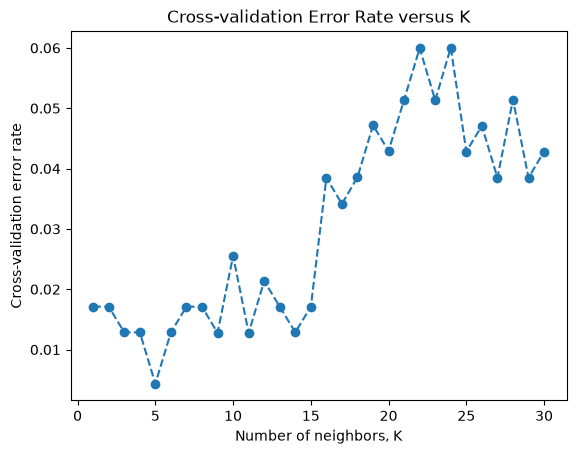

In [18]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()

ax.plot(
    list(k_values),
    validation_errors,
    marker="o",
    linestyle="--"
)

ax.set_xlabel("Number of neighbors, K")
ax.set_ylabel("Cross-validation error rate")
ax.set_title("Cross-validation Error Rate versus K")

plt.show()

In [19]:
best_k = list(k_values)[validation_errors.index(min(validation_errors))]
print("Best K:", best_k)
print("Minimum CV error rate:", min(validation_errors))

Best K: 5
Minimum CV error rate: 0.004347826086956608


#### 3.2 Importance of standardization and appropriate value of $K$ (5 points)

Explain why standardization is important for KNN and why a very small or very large value of $K$ may not perform well.

KNN uses distances to classify observations. If the predictors have different scales, the one with larger values may affects the distances more than others. Standardization can fix it. When K is very small, the model is more sensitive to noise and the predictions fluctuate too much,leading to high variance and overfitting. When K is very large, the model is less sensitive to noise, may miss important patterns in the data , leading to high bias and underfitting.

#### 3.3. Evaluate the final KNN model (10 points)

After selecting $K$, evaluate the final model on the test data. Report:

- Test accuracy (1 point)
- Test error rate (1 point)
- Confusion matrix (1 point)
- Precision, recall, and F1-score for each species (3 points)
- A written interpretation of the results (4 points)

In [23]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [24]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, predictions)
error_rate = 1 - accuracy

print("Test accuracy:", accuracy)
print("Test error rate:", error_rate)

Test accuracy: 0.99
Test error rate: 0.010000000000000009


In [25]:
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(y_test, predictions)

matrix_df = pd.DataFrame(
    matrix,
    index=["Actual: Adelie", "Actual: Chinstrap", "Actual: Gentoo"],
    columns=["Predicted: Adelie", "Predicted: Chinstrap", "Predicted: Gentoo"]
)

matrix_df

,Predicted: Adelie,Predicted: Chinstrap,Predicted: Gentoo
Actual: Adelie,44,0,0
Actual: Chinstrap,1,19,0
Actual: Gentoo,0,0,36


In [26]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    predictions,
    target_names=["Adelie", "Chinstrap", "Gentoo"],
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()
report_df.round(3)

,precision,recall,f1-score,support
Adelie,0.978,1.000,0.989,44.00
Chinstrap,1.000,0.950,0.974,20.00
Gentoo,1.000,1.000,1.000,36.00
accuracy,0.990,0.990,0.990,0.99
macro avg,0.993,0.983,0.988,100.00
weighted avg,0.990,0.990,0.990,100.00


The KNN model performs well on this test data, with test accuracy 0.99 and error rate 0.1. Gento has teh best perforamce with precision, recall and f1-score all equal to one. For Adelie, the precision is 0.978 and f1-scoer is 0.989. For Chinstrap, the recall is 0.950 and f1-score is 0.974. 
In conclusion, although the modle makes some mistakes, it performs well in classifying the penguin species.

### 4. Streamlit application (50 points)

Create an interactive Streamlit application that allows a user to enter the characteristics of a new penguin and receive a predicted species.

The application must include:

- A title and short description of the project
- Input widgets for the predictor variables
- A button labeled **Predict Species**
- The predicted penguin species
- Predicted probabilities for the three classes
- The value of $K$ selected by cross-validation
- A brief explanation of the prediction

The dataset may be loaded directly from the public URL using:

```python
data_url = (
    "https://raw.githubusercontent.com/allisonhorst/"
    "palmerpenguins/main/inst/extdata/penguins.csv"
)
df = pd.read_csv(data_url)
```

The app must be deployed publicly using [Streamlit Community Cloud](https://streamlit.io/cloud). Submit a public URL that opens without requiring the instructor to run the code locally.

####  Required submission files

Submit:

1. The Jupyter notebook used for the analysis
2. `app.py`, containing the Streamlit application
3. `requirements.txt`
4. A public GitHub repository link
5. A public Streamlit application link 
6. Any additional files required to run the application

Your GitHub repository should contain at least:

```text
penguin-classification/
├── app.py
├── requirements.txt
├── README.md
└── analysis.ipynb
```